# Experiment 5: AdaBoost and XGBoost Classification
Run the code cells from top to bottom.

In [1]:
# Theory

# Ensemble learning combines several models to produce one final prediction. Boosting builds
# learners sequentially so later learners address earlier weaknesses. AdaBoost combines weak
# classifiers using weighted voting. A decision stump is a decision tree with only one split and
# is a common weak learner. Training samples initially have equal importance in AdaBoost. The
# weights of misclassified samples increase so later learners focus more on them. The number of
# estimators controls how many weak learners may be trained. The learning rate controls the
# contribution of each learner to the ensemble.

# XGBoost is an efficient implementation of gradient boosted decision trees. It adds trees that
# improve an objective based on prediction loss and regularization. Regularization helps control
# complexity, although XGBoost can still overfit. Tree depth, learning rate and the number of
# estimators affect performance. The built-in breast cancer dataset has two classes: malignant
# and benign.

# Both models use the same stratified train-test split for a consistent comparison. Tree-based
# learners do not normally require standardization of numerical inputs. Accuracy reports the
# percentage of correct classifications on the test data. The confusion matrix reveals the types
# of mistakes made by each classifier. Precision, recall and F1 are especially useful when
# different errors have different costs. The bar chart compares test accuracy without assuming
# either algorithm must win. One train-test split illustrates performance but does not establish
# a universal best model.

In [2]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from xgboost import XGBClassifier

In [3]:
# Load a built-in binary classification dataset
cancer = load_breast_cancer()
X, y = cancer.data, cancer.target
print("Dataset shape:", X.shape)
print("Classes:", cancer.target_names)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

Dataset shape: (569, 30)
Classes: ['malignant' 'benign']


In [4]:
# Create AdaBoost using decision stumps as weak learners
ada = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=1),
    n_estimators=50, learning_rate=0.5, random_state=42)

In [5]:
# Create a small XGBoost classifier
xgb = XGBClassifier(n_estimators=50, max_depth=3,
                    learning_rate=0.1, eval_metric='logloss', random_state=42)

In [6]:
# Train and evaluate both models using the same test set
scores = []
for name, model in [('AdaBoost', ada), ('XGBoost', xgb)]:
    model.fit(X_train, y_train)
    prediction = model.predict(X_test)
    score = accuracy_score(y_test, prediction) * 100
    scores.append(score)
    print("\n", name, "Accuracy:", score)
    print("Confusion Matrix:\n", confusion_matrix(y_test, prediction))
    print(classification_report(y_test, prediction, target_names=cancer.target_names))


 AdaBoost Accuracy: 95.6140350877193
Confusion Matrix:
 [[38  4]
 [ 1 71]]
              precision    recall  f1-score   support

   malignant       0.97      0.90      0.94        42
      benign       0.95      0.99      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114




 XGBoost Accuracy: 93.85964912280701
Confusion Matrix:
 [[38  4]
 [ 3 69]]
              precision    recall  f1-score   support

   malignant       0.93      0.90      0.92        42
      benign       0.95      0.96      0.95        72

    accuracy                           0.94       114
   macro avg       0.94      0.93      0.93       114
weighted avg       0.94      0.94      0.94       114



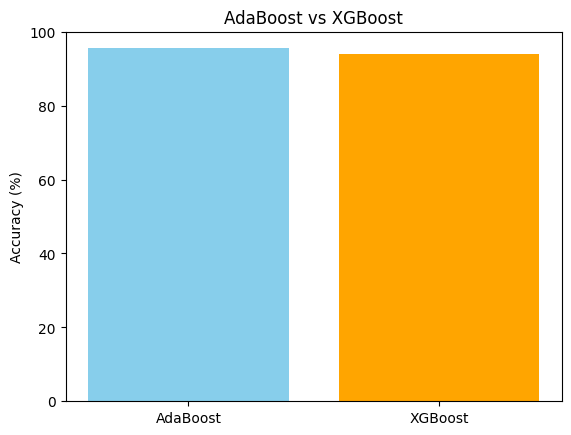

In [7]:
# Compare test accuracy visually
plt.bar(['AdaBoost', 'XGBoost'], scores, color=['skyblue', 'orange'])
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)
plt.title("AdaBoost vs XGBoost")
plt.show()